# 00 · Before trading: understand what decides the winner

**Beginner tutorial · about 25–35 minutes.** Read this notebook before notebook 01.
No finance or programming background is assumed. Read the explanation above each
cell, run the cell, then use the reading guide below its output.

**Our question:** does a clearly defined comparison of recorded reference values
reproduce the recorded winner? This is a data investigation, not a trading test.

By the end you should be able to explain a five-minute window, a threshold K,
a TWAP, a proxy outcome, and why matching historical winners is useful but does
not prove the official rule. Notebook 01 then asks whether our model would have
bought a token at an attractive price.

**Run safely:** use the project Python environment as the kernel, then choose
**Restart Kernel and Run All**. The `Lab()` below reads existing local warehouse
files. It does not open a feed, place an order or modify the warehouse. This is
an offline notebook; its calculations may take seconds. See [README](README.md)
for setup and the default dataset. The current helpers can create reusable research-cache files under `var/research/strategy_replay/cache`; the source warehouse is read-only.

## 1. Market basics and the data we will read

A **window** is one scheduled five-minute event, for example 17:50–17:55 UTC.
It has two outcome tokens, **Up** and **Down**. In the simplified binary
accounting used for research, one winning net share pays one unit of
collateral and a losing share pays zero. Official payout semantics remain
subject to verification; a recorded numeric vector is not itself dollar cash.

**`settlement_value` intuition:** buy an outcome only when its conservative
expected payout sufficiently exceeds the total purchase cost, then hold to
resolution. It buys one selected side or neither; it is not a buy-both hedge.
**Settlement** means deciding the official payout. It is different from a
resale, and different from the cash arriving after redemption.

Three names you will meet:

- **K / threshold / price to beat:** the starting reference value used in
  the candidate comparison. `exact` below means an exact timestamp match,
  not an officially verified threshold.
- **TWAP:** time-weighted average price. Long-lasting prices receive more
  weight than brief prices. A TWAP-60 report summarizes a declared 60-second
  lookback; it is not automatically the latest spot trade.
- **Proxy label:** a research stand-in for the winner. When the recorded
  payout vector has exactly one positive entry, the helper maps its index
  to Up or Down. `[1000000, 0]` does **not** mean a million-dollar profit.
  The payout unit remains unknown; conflicting/ambiguous vectors are excluded.

**Where the data comes from:** `Lab()` opens a collection in
`var/warehouse_btc5m`. Its catalog reads normalized market metadata,
instrument identities and resolution observations. The diagnostic helper
then reads `reference_observations`, including the recorded PolyBolt TWAP
values. These are provider observations stored locally, not downloaded now.

**Clocks:** `source_time` describes a provider timestamp; `received_at` is
when our collector saw the report. This notebook compares historical source
boundaries retrospectively. It may inspect later outcomes and latest stored
reports; those must never become early trading features. The notebook-01
replay separately enforces historical information availability.

A catalog includes future discovered markets too. “Windows in catalog” is
therefore not the number of complete, labeled five-minute experiments.

**Read the next cell:** `Lab` locates the dataset; `settlement_rule_table`
builds one row per catalog window. The printed label count tells you how
many windows have a usable proxy winner, before checking boundary ticks.
You do not need to understand the helper internals to read the results.

In [1]:
import json

import matplotlib.pyplot as plt

from tyrex_pm.research.strategy_lab.diagnostics import agreement_summary, settlement_rule_table
from tyrex_pm.research.strategy_lab.experiments import Lab

lab = Lab()
table = settlement_rule_table(lab.catalog)
print(f"windows in catalog: {len(table)}; with proxy label: {table['proxy_winner'].notna().sum()}")

windows in catalog: 342; with proxy label: 59


## 2. Read the contract description before interpreting prices

The next cell prints **recorded market metadata**: descriptive information
collected from Gamma, Polymarket's market-information service. `rules_text`
describes the event; `resolution_source` names a reference; `cryptoMarketConfig`
contains provider settings such as `twapLookbackSeconds`.

Read `60` as a lookback in **seconds**, not 60 trades and not a five-minute
average. The five-minute trading window and the reference's averaging length
are different concepts.

We inspect a metadata row retrospectively here. This does not establish the
exact averaging weights, boundary selection, finality or equivalence to a live
feed. Nor may a trading decision use metadata first received later in the window.

In [2]:
row = lab.catalog.gamma_rows(lab.windows()[0].market_id)[-1]
print(row['rules_text'])
print('resolution_source:', row['resolution_source'])
print('cryptoMarketConfig:', json.loads(row['additional_fields']).get('cryptoMarketConfig'))

This market will resolve to "Up" if the time-weighted average price (TWAP) of Bitcoin, generated by Chainlink, of the time range specified in the title is greater than or equal to the price at the beginning of that range. Otherwise, it will resolve to "Down".
The resolution source for this market is information from Chainlink, specifically the BTC/USD TWAP data stream available at https://data.chain.link/streams/btc-usd-twap-60s-streams.
Please note that this market is about the price according to the TWAP Chainlink data stream for the asset pair BTC/USD, not according to any other sources or spot markets.
resolution_source: https://data.chain.link/streams/btc-usd-twap-60s-streams
cryptoMarketConfig: {'asset': 'btc', 'duration': '5m', 'id': 'btc-5m-twap-60', 'twapEnabled': True, 'twapLookbackSeconds': 60}


### Tiny example: why spot and an average can disagree

Suppose K is 100. The last three **equally spaced** reference prices are
103, 101 and 99. Their simple average is 101, while the last price is 99.
Comparing the average with K suggests Up; comparing only the last price
suggests Down. This toy uses three points solely to teach the distinction.
It does not reproduce the provider's actual 60-second weighting.

In [3]:
from decimal import Decimal

toy_k = Decimal("100")
toy_prices = [Decimal("103"), Decimal("101"), Decimal("99")]
toy_average = sum(toy_prices) / len(toy_prices)
print("Synthetic example only; not recorded BTC data")
print("Last price:", toy_prices[-1], "->", "UP" if toy_prices[-1] >= toy_k else "DOWN")
print("Equal-time average:", toy_average, "->", "UP" if toy_average >= toy_k else "DOWN")

Synthetic example only; not recorded BTC data
Last price: 99 -> DOWN
Equal-time average: 101 -> UP


## 3. Test three candidate boundary alignments

We use the reference report whose provider **source second** matches the window
start as candidate K. We then compare it with the report at window end, or one
second either side. The assumed comparison is `close >= K` → Up; otherwise Down.

**What varies:** the close report's timestamp, at −1, 0 or +1 seconds.
**What does not vary:** all three candidates use the recorded TWAP stream.
This table does **not** compare raw Binance endpoint prices with TWAP, fit a
probability model, or backtest a strategy. ±1 second is an alignment diagnostic,
not a permissible way to choose a more profitable settlement rule.

The function returns an agreement summary. For each candidate, divide `agree`
by `windows_evaluable`. Missing observations are excluded, not counted as losses.

In [4]:
agreement_summary(table)

,candidate_rule,windows_evaluable,agree,disagree,agreement_rate
0,TWAP(close-1s) >= TWAP(start),56,54.0,2.0,0.964286
1,TWAP(close+0s) >= TWAP(start),56,54.0,2.0,0.964286
2,TWAP(close+1s) >= TWAP(start),56,54.0,2.0,0.964286
3,(windows without proxy label or ticks),286,NaN,NaN,NaN


**How to interpret this table:** `windows_evaluable` is the denominator for
that row; `agreement_rate = 1` means agreement on all of those windows.
The final row counts exclusions and is not another candidate rule.
Three checks on the same windows are not three independent datasets.
They do not estimate a trader's win rate or expected profit.

In [5]:
cols = ['slug', 'proxy_winner', 'k_exact', 'close_+0s', 'margin_usd_0s',
        'rule_+0s', 'agrees_+0s', 'k_receive_lag_ms']
table.dropna(subset=['proxy_winner'])[cols].head(20)

,slug,proxy_winner,k_exact,close_+0s,margin_usd_0s,rule_+0s,agrees_+0s,k_receive_lag_ms
0,btc-updown-5m-1791297000,UP,None,86122.354740515596926976000000000000,NaN,NaN,None,NaN
1,btc-updown-5m-1791297300,UP,86122.354740515596926976000000000000,86201.897951123413663744000000000000,79.543211,UP,True,87561.1200
2,btc-updown-5m-1791297600,UP,86201.897951123413663744000000000000,86294.172763894914744320000000000000,92.274813,UP,True,460.0201
3,btc-updown-5m-1791297900,DOWN,86294.172763894914744320000000000000,86264.740235673098780672000000000000,-29.432528,DOWN,True,724.3045
4,btc-updown-5m-1791298200,UP,86264.740235673098780672000000000000,86412.524360612181966848000000000000,147.784125,UP,True,947.7588
5,btc-updown-5m-1791298500,UP,86412.524360612181966848000000000000,86585.629817584488546304000000000000,173.105457,UP,True,1012.2653
6,btc-updown-5m-1791298800,DOWN,86585.629817584488546304000000000000,86559.412278021259788288000000000000,-26.217540,DOWN,True,1051.6951
7,btc-updown-5m-1791299100,UP,86559.412278021259788288000000000000,86571.215034961478287360000000000000,11.802757,UP,True,1582.5007
8,btc-updown-5m-1791299400,UP,86571.215034961478287360000000000000,86587.362671335923777536000000000000,16.147636,UP,True,1141.3000
9,btc-updown-5m-1791299700,DOWN,86587.362671335923777536000000000000,86561.823173261010141184000000000000,-25.539498,DOWN,True,1235.2263


**Column dictionary for the individual windows:**

- `slug`: the provider's human-readable market name; `market_id` is its identity.
- `proxy_winner`: Up/Down inferred from the single-positive-entry vector.
- `k_exact`: reference value matched to the opening source second.
- `close_+0s`: value matched to the scheduled closing source second.
- `margin_usd_0s`: closing value minus opening value, in the USD reference unit.
- `rule_+0s`: winner predicted by the candidate comparison.
- `agrees_+0s`: whether that prediction equals the proxy winner.
- `k_receive_lag_ms`: how late the opening report reached the collector.

`NaN`/`None` means unavailable, not zero. Choose one row and subtract K from
its close value. Check the sign against `rule_+0s`. This is a rule diagnostic;
there is no entry price, fee or position in this row.

## 4. Read the two histograms: distance and information arrival

**Left chart:** each window contributes `TWAP(close) − TWAP(start)`, expressed
in reference-price dollars per BTC. The horizontal axis is that difference;
the vertical axis counts windows in each range. Positive values imply Up
under this candidate rule; negative values imply Down. Zero is an exact tie.
This is a BTC reference-price difference, **not our trading profit**.

**Right chart:** the horizontal axis is milliseconds between scheduled open
and local receipt of the candidate opening report; the vertical axis counts
windows. 1,000 ms = one second. A report about 17:50:00 received at 17:50:01.2
was unavailable to the trader at 17:50:00, even though its source time says open.

The chart clips delays above 5,000 ms to 5,000. A bar at the right edge can
include much longer delays: clipping makes the plot readable, not the data
better. These plots require boundary values but not necessarily a proxy winner,
so their sample count may differ from the agreement table.

smallest |margin| USD: 1.4500437090883338 · exact ties: 0


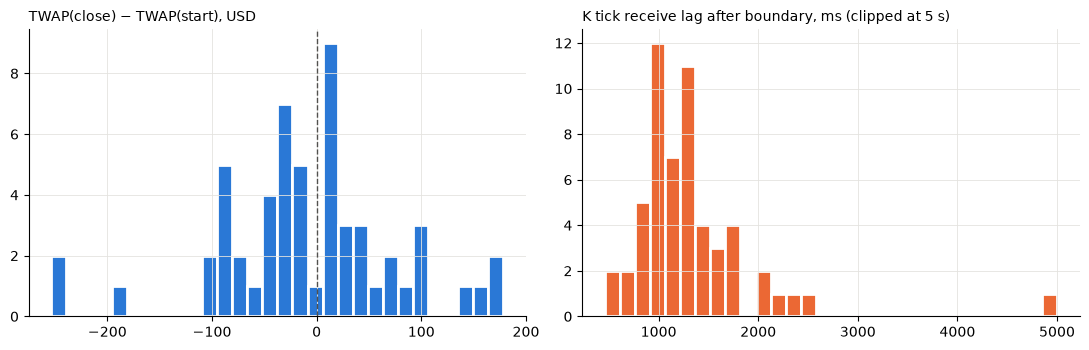

In [6]:
labelled = table.dropna(subset=['margin_usd_0s'])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(labelled['margin_usd_0s'], bins=30, color='#2a78d6', edgecolor='white', linewidth=2)
axes[0].axvline(0, color='#52514e', lw=1, ls='--')
axes[0].set_title('TWAP(close) − TWAP(start), USD', loc='left', fontsize=10)
axes[1].hist(labelled['k_receive_lag_ms'].clip(upper=5000), bins=30, color='#eb6834',
             edgecolor='white', linewidth=2)
axes[1].set_title('K tick receive lag after boundary, ms (clipped at 5 s)', loc='left', fontsize=10)
for a in axes:
    a.spines[['top', 'right']].set_visible(False)
    a.grid(True, color='#e4e3df', lw=0.6)
fig.tight_layout()
print('smallest |margin| USD:', labelled['margin_usd_0s'].abs().min(),
      '· exact ties:', int(labelled['tie_0s'].sum()))

**Inspect the outliers instead of hiding them.** The following values use
the original delays, without the chart's clipping. A large delay changes
when a strategy could know K; it does not move the scheduled window start.

In [7]:
table[["slug", "k_receive_lag_ms"]].dropna().nlargest(5, "k_receive_lag_ms")

,slug,k_receive_lag_ms
1,btc-updown-5m-1791297300,87561.1200
41,btc-updown-5m-1791309300,2488.2636
56,btc-updown-5m-1791313800,2414.9424
38,btc-updown-5m-1791308400,2134.5793
42,btc-updown-5m-1791309600,2084.1880


## 5. What have we learned, and what remains unknown?

Read the current output rather than memorizing a success rate:

- High agreement supports a candidate interpretation on the evaluable sample.
  It does not verify the provider's units or exact official settlement procedure.
- If all three offsets agree equally well, these windows do not distinguish
  their boundary conventions. That is an unresolved question, not three proofs.
- `exact ties = 0` means the tie convention has not been tested. Assuming Up
  on equality must remain explicit.
- Missing boundary reports or labels explain exclusions; they are not evidence
  that a candidate rule is wrong.
- A reference with averaging and publication lag motivates a different forecast
  from a simple endpoint model on spot. We still need the actual functional and
  relevant history before calling that forecast an official-contract model.

The evidence and open questions are tracked in
[the S0 interpretation report](../../../../Docs/implementation/strategies/s0_data_interpretation.md).
Current values can change when the dataset or helpers change; follow the labels.

**Your handoff to notebook 01:** we can explore what a strategy would decide
under declared assumptions. Agreement here is not a reason to call its model
accurate, its fills realistic or its profit validated.

## Check your understanding

1. If every evaluable window agrees, have we measured strategy profitability?
2. Could K be used at open if its report arrived two seconds later?
3. Does a payout entry of 1,000,000 establish a dollar payout?
4. If every close is far from K, have we tested equality handling?

**Suggested answers:** (1) No: we tested a winner comparison, not trading.
(2) No: availability starts at receipt, with any additional modeled delay.
(3) No: units and mapping require evidence; here we infer only a proxy index.
(4) No: we have no observations of the tie case.

**Next:** open [01_settlement_value.ipynb](01_settlement_value.ipynb).
Keep three separate questions in mind: *What event decides the winner?*
*How well do we forecast it?* *Can we buy at an attractive total cost?*